In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import kagglehub
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

/kaggle/input/competitions/store-sales-time-series-forecasting/oil.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/sample_submission.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/holidays_events.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/stores.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/train.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/test.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/transactions.csv


In [2]:
data_path = Path('/kaggle/input/competitions/store-sales-time-series-forecasting')

files = list(data_path.glob('*.csv'))

dataframes = {}

for file in files:
    name = file.stem
    dataframes[name] = pd.read_csv(file)

# Check file
for name, df in dataframes.items():
    print(name, df.shape)

oil (1218, 2)
sample_submission (28512, 2)
holidays_events (350, 6)
stores (54, 5)
train (3000888, 6)
test (28512, 5)
transactions (83488, 3)


In [3]:
def inspect_dataset(df, name):
    print(f'\n---{name}---')
    print(f'Rows: {df.shape[0]} --- Cols: {df.shape[1]}')

    print(f'\nData Types:')
    display(df.dtypes.to_frame(name='Data Type'))

    print(f'\nMissing Values:')
    missing = df.isna().sum()
    display(missing[missing > 0].to_frame(name='Missing Vales'))

In [4]:
inspect_dataset(dataframes['train'], 'Train')
inspect_dataset(dataframes['test'], 'Test')


---Train---
Rows: 3000888 --- Cols: 6

Data Types:


,Data Type
id,int64
date,object
store_nbr,int64
family,object
sales,float64
onpromotion,int64



Missing Values:


,Missing Vales



---Test---
Rows: 28512 --- Cols: 5

Data Types:


,Data Type
id,int64
date,object
store_nbr,int64
family,object
onpromotion,int64



Missing Values:


,Missing Vales


# Exploratoy Analysis

In [5]:
# Check metrics of train set
dataframes['train']['sales'].describe()

count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64

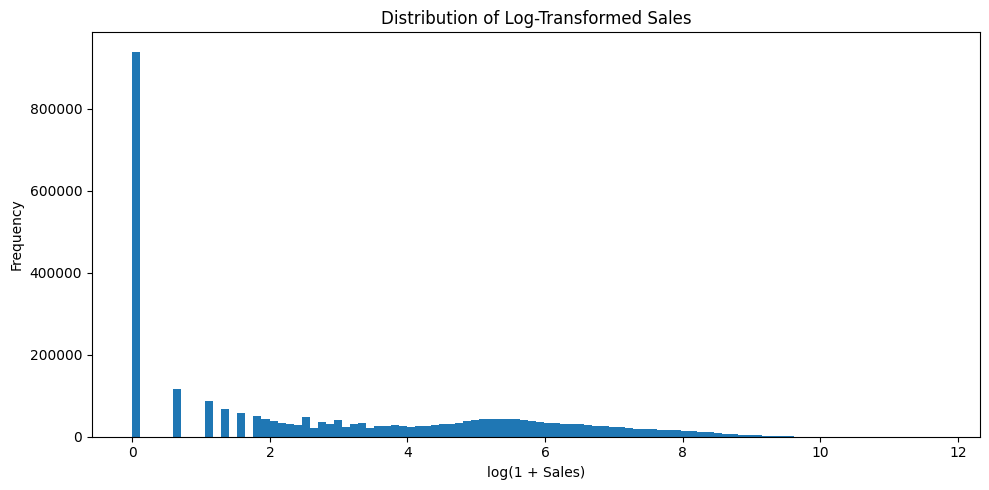

In [6]:
sales = dataframes['train']['sales']

plt.figure(figsize=(10, 5))
plt.hist(np.log1p(sales), bins=100)

plt.title('Distribution of Log-Transformed Sales')
plt.xlabel('log(1 + Sales)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

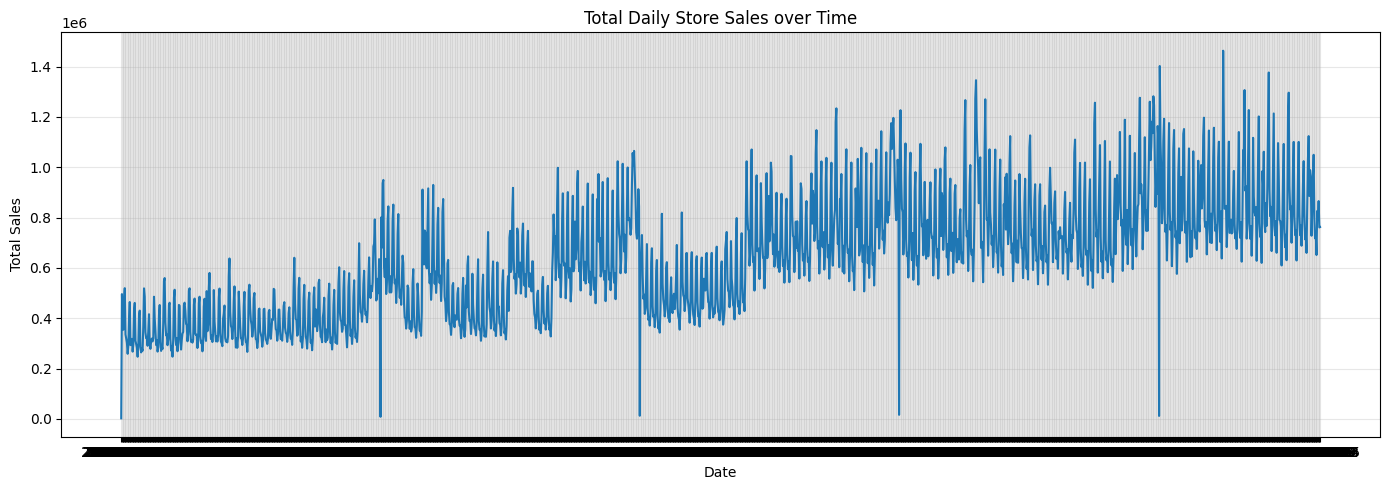

In [7]:
# Sales Distribution over time
daily_sales = dataframes['train'].groupby('date')['sales'].sum()
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title('Total Daily Store Sales over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Sales Trends Over Time

- **Year-over-year growth:** Total sales show an overall upward trend from year to year.
- **Seasonality:** Sales tend to be relatively low at the beginning of the year, particularly during the first three years.
- **Potential pattern:** This may indicate a recurring seasonal effect that should be investigated further during feature engineering.

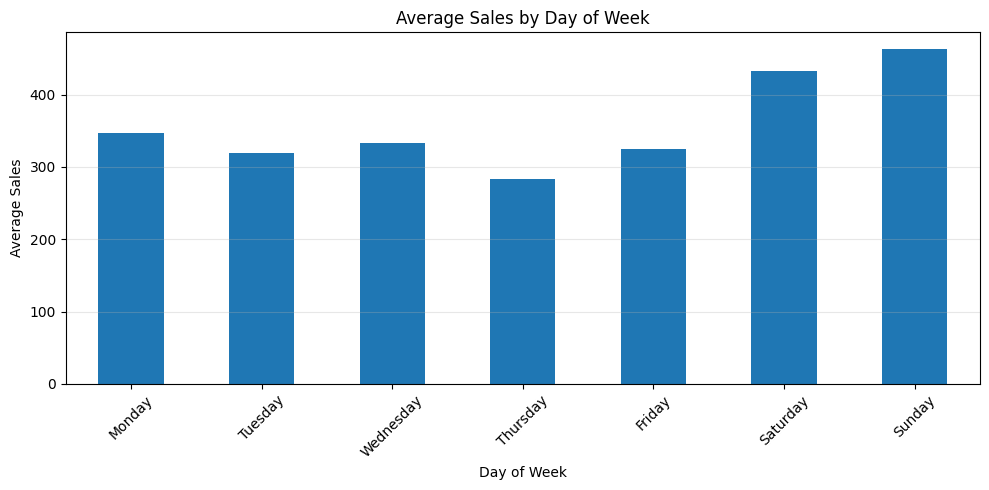

In [8]:
# Avg. Sales by Day of Week
train = dataframes['train'].copy()

train['date'] = pd.to_datetime(train['date'])
train['day_of_week'] = train['date'].dt.day_name()

weekday_sales = (
    train.groupby('day_of_week')['sales']
    .mean()
    .reindex([
        'Monday', 'Tuesday', 'Wednesday', 'Thursday', 
        'Friday', 'Saturday', 'Sunday'
    ])
)

plt.figure(figsize=(10, 5))
weekday_sales.plot(kind='bar')# 
plt.title('Average Sales by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Average Sales by Day of Week

- **Highest sales:** Saturday and Sunday show the highest average sales.
- **Lowest sales:** Thursday has the lowest average sales.
- **Potential insight:** Sales may vary systematically by day of the week, suggesting that weekday information could be a useful feature for time series forecasting.

*Note: These results represent averages across all stores and product families. Further analysis is needed to determine whether the pattern holds for individual stores and product families.*

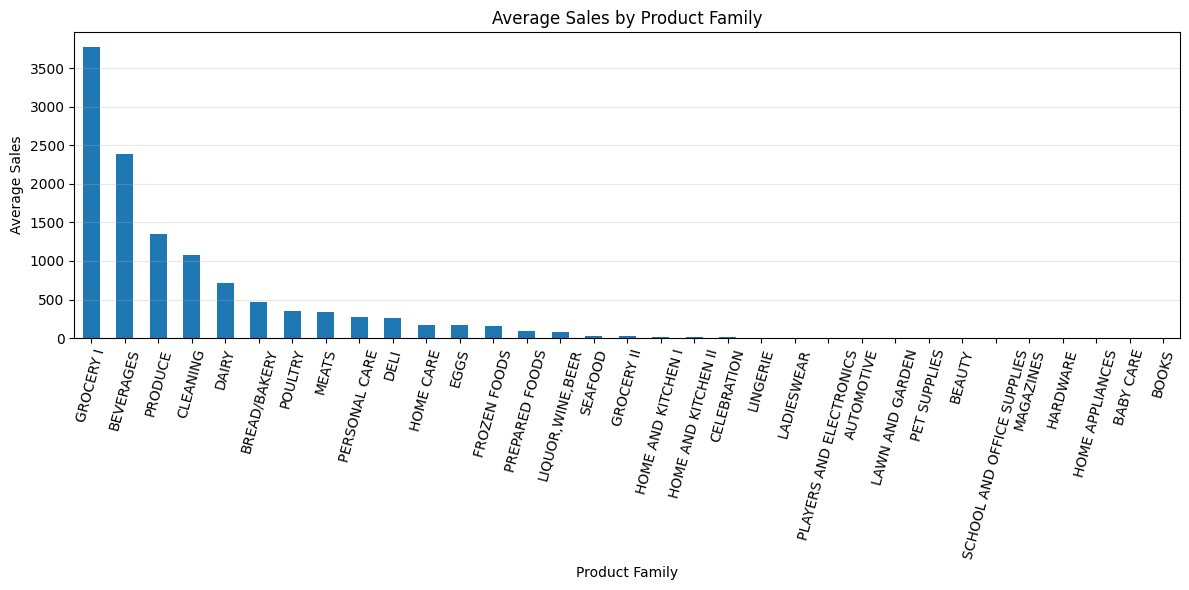

In [9]:
# Avg Sales by Product Family

family_sales = (
    train.groupby('family')['sales']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))
family_sales.plot(kind='bar')
plt.title('Average Sales by Product Family')
plt.xlabel('Product Family')
plt.ylabel('Average Sales')
plt.xticks(rotation=75)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Average Sales by Product Family

- **Highest sales:** Grocery and Beverages have the highest average sales among all product families.
- **Key insight:** Sales vary considerably across product families, suggesting that product category is an important factor in forecasting.
- **Modeling implication:** Product family should be included as a categorical feature in the forecasting model.

*Note: Average sales per observation do not necessarily represent total revenue across the entire dataset.*

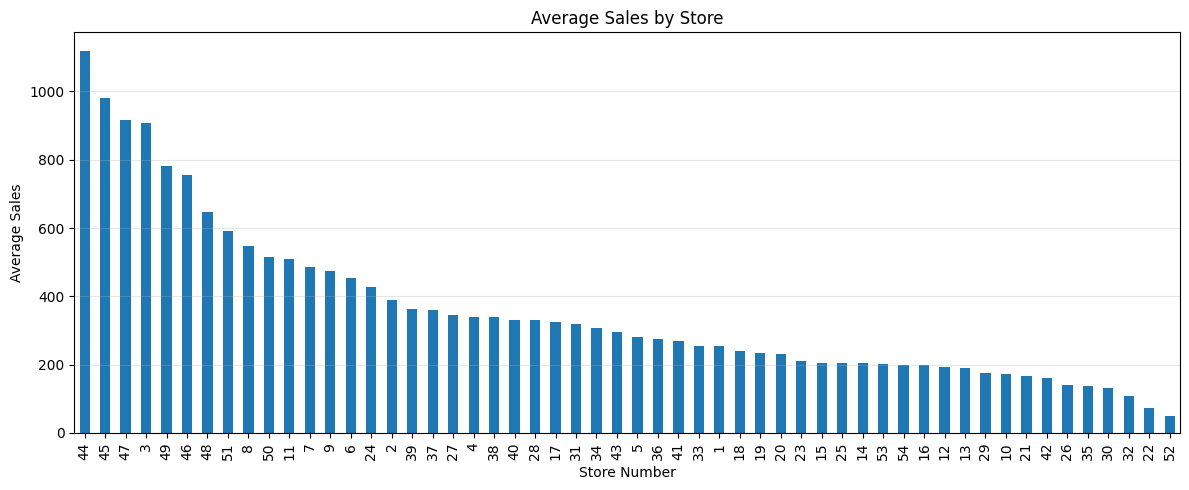

In [10]:
# Averages Sales by Store
store_sales = (
    train.groupby('store_nbr')['sales']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,5))
store_sales.plot(kind='bar')
plt.title('Average Sales by Store')
plt.xlabel('Store Number')
plt.ylabel('Average Sales')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Average Sales by Store

- **Highest average sales:** Store 44 ranks first, followed by stores 45, 47, 3, 49, and 46.
- **Key insight:** Average sales differ across stores, suggesting that store-specific characteristics may influence sales performance.
- **Modeling implication:** `store_nbr` should be considered as a categorical feature in the forecasting model.

*Note: These rankings are based on average sales per observation, not total sales across the entire dataset.*

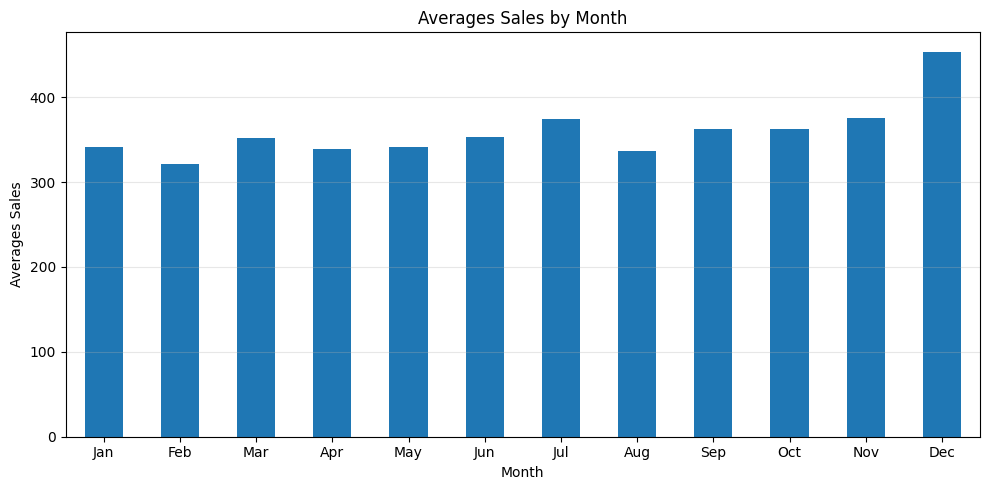

In [11]:
# Averages Sales by Month
train['month'] = train['date'].dt.month

monthly_sales = (
    train.groupby('month')['sales']
    .mean()
)

plt.figure(figsize=(10,5))
monthly_sales.plot(kind='bar')
plt.title('Averages Sales by Month')
plt.xlabel('Month')
plt.ylabel('Averages Sales')
plt.xticks(
    ticks=range(12),
    labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep',
           'Oct', 'Nov', 'Dec'],
    rotation=0
)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Average Sales by Month

- **Overall pattern:** Average sales remain relatively stable throughout the year.
- **December:** Sales show a slight increase compared to other months.
- **Modeling implication:** Month may still be a useful time-based feature, although the monthly differences appear relatively small.

*Note: Averaging across all years, stores, and product families may hide more specific seasonal patterns.*

is_promotion
False     158.246681
True     1137.693730
Name: sales, dtype: float64


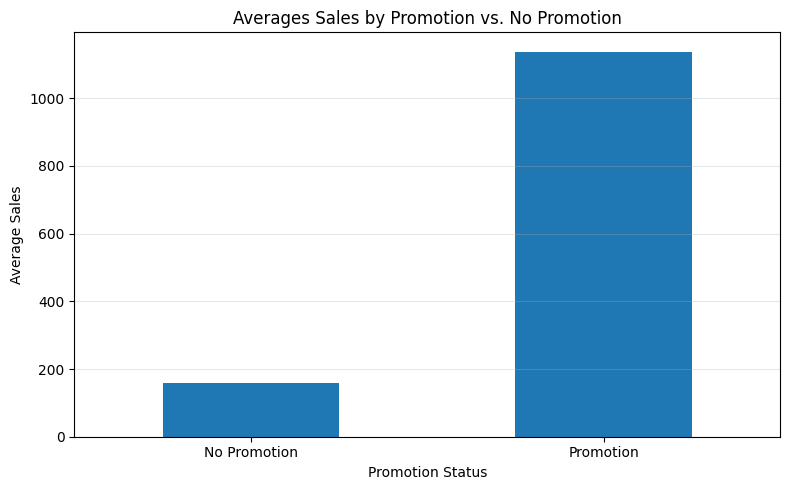

In [12]:
# Averages Sales by Promotion Status
train['is_promotion'] = train['onpromotion'] > 0

promotion_sales = (
    train.groupby('is_promotion')['sales']
    .mean()
)

print(promotion_sales)
promotion_sales.plot(kind='bar', figsize=(8,5))
plt.title('Averages Sales by Promotion vs. No Promotion')
plt.xlabel('Promotion Status')
plt.ylabel('Average Sales')
plt.xticks(
    ticks=[0, 1],
    labels=['No Promotion', 'Promotion'],
    rotation=0
)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Promotion Impact on Sales

- **No promotion:** Average sales are approximately 158.25.
- **Promotion:** Average sales are approximately 1,137.69.
- **Key insight:** Observations with promotions have substantially higher average sales than observations without promotions.
- **Modeling implication:** The `onpromotion` feature may be highly informative for sales forecasting.

*Note: This is an observational comparison, not proof of causation. Differences in product families, stores, and promotion frequency may influence the results.*

In [13]:
# Promtion Frequency
promotion_counts = train['is_promotion'].value_counts()
promotion_percentage = (
    train['is_promotion']
    .value_counts(normalize=True) * 100
)
print('Observation Counts:')
print(promotion_counts)
print('\nPercentage of observations:')
print(promotion_percentage.round(2))

Observation Counts:
is_promotion
False    2389559
True      611329
Name: count, dtype: int64

Percentage of observations:
is_promotion
False    79.63
True     20.37
Name: proportion, dtype: float64


### Promotion Frequency

- **No promotion:** 2,389,559 observations (79.63%).
- **Promotion:** 611,329 observations (20.37%).
- **Key insight:** Approximately one in five observations involves at least one promoted product.
- **Modeling implication:** `onpromotion` may provide valuable predictive information, while its distribution and relationship with sales should be considered during feature engineering.

*Note: Promotion status is defined as `onpromotion > 0`. Each observation represents a store–product-family–date combination.*

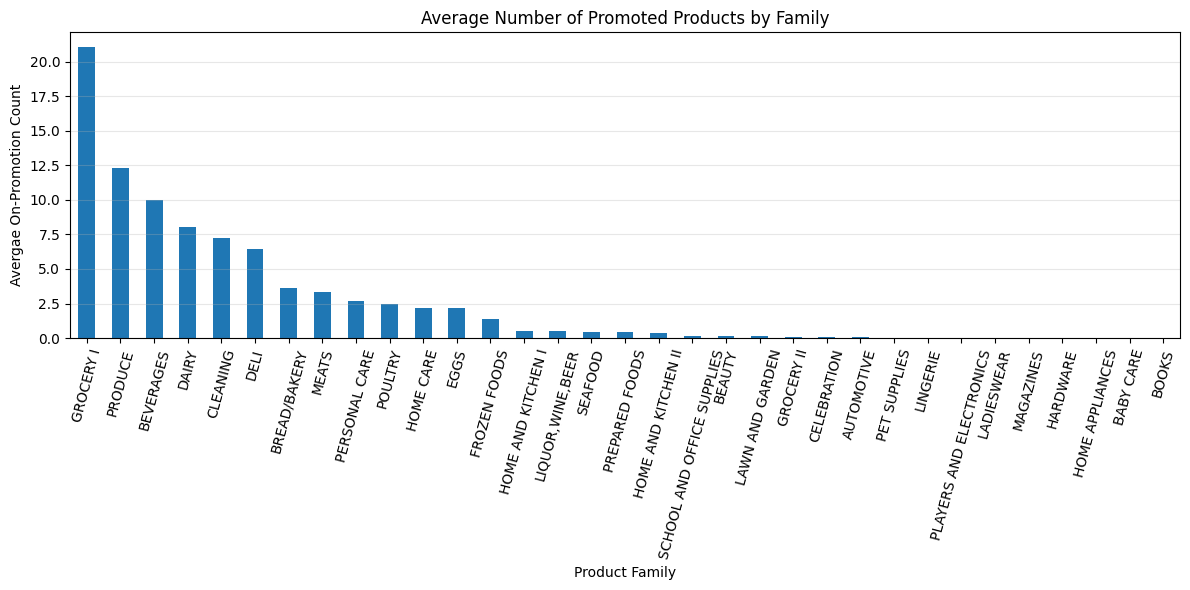

In [14]:
# Promotion Frequency by Product Family
promotion_by_family = (
    train.groupby('family')['onpromotion']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))
promotion_by_family.plot(kind='bar')
plt.title('Average Number of Promoted Products by Family')
plt.xlabel('Product Family')
plt.ylabel('Avergae On-Promotion Count')
plt.xticks(rotation=75)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Promotion Activity by Product Family

- **Grocery:** Has the highest average `onpromotion` count, exceeding 20.
- **Produce:** Ranks second, with an average of approximately 12.5.
- **Beverages:** Follows with an average of approximately 10.
- **Key insight:** Promotion activity varies considerably across product families, with Grocery receiving particularly high promotional activity.
- **Modeling implication:** The relationship between promotions and sales may differ by product family, making their interaction worth investigating during feature engineering.

*Note: These values represent the average `onpromotion` count, not the percentage of observations with promotions.*

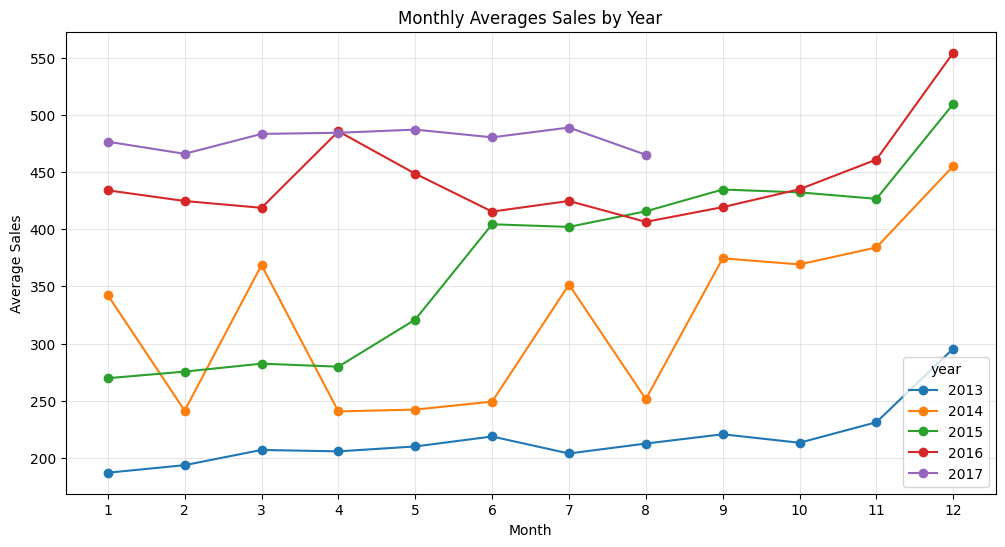

In [15]:
# Monthly Sales by Year
train['year'] = train['date'].dt.year
train['month'] = train['date'].dt.month

monthly_sales = (
    train.groupby(['year', 'month'])['sales']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12,6))

for year, group in monthly_sales.groupby('year'):
    plt.plot(
        group['month'],
        group['sales'],
        marker='o',
        label=year
    )

plt.title('Monthly Averages Sales by Year')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.xticks(range(1,13))
plt.legend(title='year')
plt.grid(alpha=0.3)

### Monthly Sales Patterns Across Years

- **2013:** Lowest overall sales levels among the observed years.
- **2014:** Sales fluctuate throughout the year, with an increase toward year-end.
- **2015:** Sales begin to rise noticeably from May onward.
- **2016:** A pronounced peak occurs in April.
- **2017:** Highest overall sales levels in the observed period.

**Key insights:**
- Sales show a general upward trend over time, but the monthly patterns differ between years.
- Seasonal effects may be present, although the observed peaks are not consistent across all years.
- Year, month, and potentially year–month interactions may be useful features for forecasting.

*Note: The final year may cover only part of the year, depending on the dataset's date range. Check the available dates before comparing annual averages directly.*

In [16]:
# Check date range and observations per year
print('Date Range:')
print(train['date'].min(), 'to', train['date'].max())

print('\nObservations per year:')
print(train.groupby(train['date'].dt.year).size())

Date Range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00

Observations per year:
date
2013    648648
2014    648648
2015    648648
2016    650430
2017    404514
dtype: int64


### Dataset Date Range and Yearly Coverage

- **Date range:** January 1, 2013 – August 15, 2017.
- **2013–2015:** Each year contains 648,648 observations.
- **2016:** Contains 650,430 observations.
- **2017:** Contains 404,514 observations and covers only part of the year.

**Key insight:** The dataset contains an incomplete final year, which makes direct comparisons of annual total sales misleading.

**Modeling implication:** Time-based validation should respect chronological order, and seasonal comparisons should account for incomplete periods.

# Feature Engineering

In [17]:
for name, df in dataframes.items():
    print(f'\n{name}: {df.shape}')
    print(df.dtypes)
    print('Duplicates:', df.duplicated().sum())


oil: (1218, 2)
date           object
dcoilwtico    float64
dtype: object
Duplicates: 0

sample_submission: (28512, 2)
id         int64
sales    float64
dtype: object
Duplicates: 0

holidays_events: (350, 6)
date           object
type           object
locale         object
locale_name    object
description    object
transferred      bool
dtype: object
Duplicates: 0

stores: (54, 5)
store_nbr     int64
city         object
state        object
type         object
cluster       int64
dtype: object
Duplicates: 0

train: (3000888, 6)
id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object
Duplicates: 0

test: (28512, 5)
id              int64
date           object
store_nbr       int64
family         object
onpromotion     int64
dtype: object
Duplicates: 0

transactions: (83488, 3)
date            object
store_nbr        int64
transactions     int64
dtype: object
Duplicates: 0


In [18]:
print('Store - Unique Store Numbers')
print(dataframes['stores']['store_nbr'].is_unique)
print('\nOil - Unique Dates')
print(dataframes['oil']['date'].is_unique)
print('\nTransaction - Unique Combination from Date and Store Number')
print(~dataframes['transactions'].duplicated(subset=['date', 'store_nbr']).any())
print('\nHolidays - Number of Events per Date')
print(
    dataframes['holidays_events']
    .groupby('date')
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Store - Unique Store Numbers
True

Oil - Unique Dates
True

Transaction - Unique Combination from Date and Store Number
True

Holidays - Number of Events per Date
date
2014-06-25    4
2016-06-25    3
2012-06-25    3
2015-06-25    3
2017-06-25    3
2013-06-25    3
2015-12-22    2
2012-12-22    2
2012-12-24    2
2012-12-31    2
dtype: int64


In [19]:
train_merged = dataframes['train'].copy()
test_merged = dataframes['test'].copy()

def merge_base_tabels(df):
    df = df.merge(
        dataframes['stores'], 
        on='store_nbr', 
        how='left', 
        validate='many_to_one'
    )

    df = df.merge(
            dataframes['oil'], 
            on='date', 
            how='left', 
            validate='many_to_one'
        )

    df = df.merge(
            dataframes['transactions'], 
            on=['date','store_nbr'], 
            how='left', 
            validate='many_to_one'
        )
    return df

train_merged = merge_base_tabels(train_merged)
test_merged = merge_base_tabels(test_merged)

print('Original Train Rows:', len(dataframes['train']))
print('Merged Train Rows:', len(train_merged))
print('\nOriginal Test Rows:', len(dataframes['test']))
print('Merged Test Rows:', len(test_merged))
print('\nMising values in merged Train:')
print(train_merged[['city', 'dcoilwtico', 'transactions']].isna().sum())
print('\nMerged Train Cols:')
print(train_merged.columns.tolist())

Original Train Rows: 3000888
Merged Train Rows: 3000888

Original Test Rows: 28512
Merged Test Rows: 28512

Mising values in merged Train:
city                 0
dcoilwtico      928422
transactions    245784
dtype: int64

Merged Train Cols:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'city', 'state', 'type', 'cluster', 'dcoilwtico', 'transactions']


In [20]:
holidays = dataframes['holidays_events']
print('Locale Events:')
print(holidays['locale'].value_counts(dropna=False))
print('\nEvent Types:')
print(holidays['type'].value_counts(dropna=False))
print('\nTransferred Values:')
print(holidays['transferred'].value_counts(dropna=False))

print('\nExamples of regional and local events:')
print(
    holidays.loc[
        holidays['locale'].isin(['Regional', 'Local']), 
        ['date', 'type', 'locale', 'locale_name', 'description', 'transferred']
    ].head(15).to_string(index=False)
)

print('\nStore Locations:')
print(
    dataframes['stores'][['store_nbr', 'city', 'state']]
    .head(10)
    .to_string(index=False)
)

Locale Events:
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64

Event Types:
type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64

Transferred Values:
transferred
False    338
True      12
Name: count, dtype: int64

Examples of regional and local events:
      date    type   locale   locale_name                   description  transferred
2012-03-02 Holiday    Local         Manta            Fundacion de Manta        False
2012-04-01 Holiday Regional      Cotopaxi Provincializacion de Cotopaxi        False
2012-04-12 Holiday    Local        Cuenca           Fundacion de Cuenca        False
2012-04-14 Holiday    Local      Libertad     Cantonizacion de Libertad        False
2012-04-21 Holiday    Local      Riobamba     Cantonizacion de Riobamba        False
2012-05-12 Holiday    Local          Puyo        Cantonizacion del Puyo        False
2012-06-23 Holiday    Local    

In [21]:
holidays = dataframes['holidays_events'].copy()
active_holidays = holidays.loc[~holidays['transferred']].copy()

event_types = [
    'Holiday', 'Event', 'Additional',
    'Transfer', 'Bridge', 'Work Day'
]

def aggregate_holidays(df, keys, prefix):
    aggregation = {
        'event_count': ('type', 'size')
    }

    for event_type in event_types:
        feature_name = (
            event_type.lower().replace(' ', '_') + '_count'
        )
        aggregation[feature_name] = (
            'type',
            lambda s, t=event_type: s.eq(t).sum()
        )

    result = (
        df.groupby(keys, as_index=False)
        .agg(**aggregation)
    )

    rename_cols = {
        col: f'{prefix}_{col}'
        for col in result.columns
        if col not in keys
    }

    return result.rename(columns=rename_cols)

national_holidays = aggregate_holidays(
    active_holidays.loc[active_holidays['locale'] == 'National'],
    ['date'],
    'national'
)

regional_holidays = aggregate_holidays(
    active_holidays.loc[active_holidays['locale'] == 'Regional'],
    ['date', 'locale_name'],
    'regional'
).rename(columns={'locale_name': 'state'})

local_holidays = aggregate_holidays(
    active_holidays.loc[active_holidays['locale'] == 'Local'],
    ['date', 'locale_name'],
    'local'
).rename(columns={'locale_name': 'city'})

print('National:', national_holidays.shape)
print('Regional:', regional_holidays.shape)
print('Local:', local_holidays.shape)

National: (160, 7)
Regional: (24, 8)
Local: (147, 8)


In [22]:
def add_holiday_features(df):
    result = df.copy()

    result = result.merge(
        national_holidays,
        on='date',
        how='left',
        validate='many_to_one'
    )

    result = result.merge(
        regional_holidays,
        on=['date', 'state'],
        how='left',
        validate='many_to_one'
    )

    result = result.merge(
        local_holidays,
        on=['date', 'city'],
        how='left',
        validate='many_to_one'
    )

    
    holiday_cols = [
        col for col in result.columns
        if col.startswith(('national_', 'regional_', 'local_'))
    ]

    result[holiday_cols] = (
        result[holiday_cols].fillna(0).astype('int16')
    )

    return result


train_merged = add_holiday_features(train_merged)
test_merged = add_holiday_features(test_merged)

print('Train shape:', train_merged.shape)
print('Test shape:', test_merged.shape)

print('\nHoliday feature examples:')
print(
    train_merged[
        ['date', 'city', 'state',
         'national_event_count',
         'regional_event_count',
         'local_event_count']
    ].head(10)
)

Train shape: (3000888, 30)
Test shape: (28512, 29)

Holiday feature examples:
         date   city      state  national_event_count  regional_event_count  \
0  2013-01-01  Quito  Pichincha                     0                     0   
1  2013-01-01  Quito  Pichincha                     0                     0   
2  2013-01-01  Quito  Pichincha                     0                     0   
3  2013-01-01  Quito  Pichincha                     0                     0   
4  2013-01-01  Quito  Pichincha                     0                     0   
5  2013-01-01  Quito  Pichincha                     0                     0   
6  2013-01-01  Quito  Pichincha                     0                     0   
7  2013-01-01  Quito  Pichincha                     0                     0   
8  2013-01-01  Quito  Pichincha                     0                     0   
9  2013-01-01  Quito  Pichincha                     0                     0   

   local_event_count  
0                  0  
1     

In [23]:
print('Original holiday entries:')
print(
    dataframes['holidays_events'].loc[
        dataframes['holidays_events']['date'].eq('2013-01-01'),
        ['date', 'type', 'locale', 'locale_name',
         'description', 'transferred']
    ]
)

print('\nAggregated national holidays:')
print(
    national_holidays.loc[
        national_holidays['date'].eq('2013-01-01')
    ]
)

print('\nMerged train rows:')
print(
    train_merged.loc[
        train_merged['date'].eq('2013-01-01'),
        ['date', 'city', 'state', 'national_event_count',
         'national_holiday_count', 'regional_event_count',
         'local_event_count']
    ].head()
)

Original holiday entries:
          date     type    locale locale_name         description  transferred
41  2013-01-01  Holiday  National     Ecuador  Primer dia del ano        False

Aggregated national holidays:
          date  national_event_count  national_holiday_count  \
11  2013-01-01                     0                       1   

    national_additional_count  national_transfer_count  national_bridge_count  \
11                          0                        0                      0   

    national_work_day_count  
11                        0  

Merged train rows:
         date   city      state  national_event_count  national_holiday_count  \
0  2013-01-01  Quito  Pichincha                     0                       1   
1  2013-01-01  Quito  Pichincha                     0                       1   
2  2013-01-01  Quito  Pichincha                     0                       1   
3  2013-01-01  Quito  Pichincha                     0                       1   
4  2013-

In [24]:
train_merged['date'] = pd.to_datetime(train_merged['date'])
test_merged['date'] = pd.to_datetime(test_merged['date'])

print('Train:', train_merged['date'].dtype)
print('Test:', test_merged['date'].dtype)

Train: datetime64[ns]
Test: datetime64[ns]


In [25]:
def add_calendar_features(df):
    result = df.copy()

    result['year'] = result['date'].dt.year
    result['month'] = result['date'].dt.month
    result['day'] = result['date'].dt.day
    result['day_of_week'] = result['date'].dt.dayofweek
    result['week_of_year'] = (
        result['date'].dt.isocalendar().week.astype('int8')
    )
    result['is_weekend'] = (
        result['day_of_week'] >= 5
    ).astype('int8')

    return result


train_merged = add_calendar_features(train_merged)
test_merged = add_calendar_features(test_merged)

In [26]:
print('Train shape:', train_merged.shape)
print('Test shape:', test_merged.shape)

print(
    train_merged[
        ['date', 'year', 'month', 'day',
         'day_of_week', 'week_of_year', 'is_weekend']
    ].head(10)
)

Train shape: (3000888, 36)
Test shape: (28512, 35)
        date  year  month  day  day_of_week  week_of_year  is_weekend
0 2013-01-01  2013      1    1            1             1           0
1 2013-01-01  2013      1    1            1             1           0
2 2013-01-01  2013      1    1            1             1           0
3 2013-01-01  2013      1    1            1             1           0
4 2013-01-01  2013      1    1            1             1           0
5 2013-01-01  2013      1    1            1             1           0
6 2013-01-01  2013      1    1            1             1           0
7 2013-01-01  2013      1    1            1             1           0
8 2013-01-01  2013      1    1            1             1           0
9 2013-01-01  2013      1    1            1             1           0


In [27]:
# Check missing values in the merged datasets

missing_train = train_merged.isna().sum()
missing_test = test_merged.isna().sum()

print('Missing values in train:')
print(missing_train[missing_train > 0].sort_values(ascending=False))

print('\nMissing values in test:')
print(missing_test[missing_test > 0].sort_values(ascending=False))

Missing values in train:
dcoilwtico      928422
transactions    245784
dtype: int64

Missing values in test:
transactions    28512
dcoilwtico       7128
dtype: int64
